# Задача 6

Решить задачу Коши

$$
    \frac{dx}{dt}=-x, \qquad x(0)=1, \qquad 0<t<3
$$

методом Эйлера первого порядка точности и методами Рунге–Кутты
второго и четвёртого порядка точности.

---

## Точное решение и равномерная сетка.

Разделим переменные:

$$
    \frac{dx}{x}=-dt \quad\Rightarrow\quad x(t)=Ce^{-t}.
$$

Из $x(0)=1$ находим $C=1$, поэтому

$$
    \boxed{x(t)=e^{-t}}, \qquad x(3)=e^{-3}\approx0.049787068367864.
$$

Точное решение используем для проверки численных методов.
Возьмём сетку $t_i=ih$, $h=3/N$, $i=0,\ldots,N$.
Значения численного решения обозначим $y_i\approx x(t_i)$.
Включим точку $t=3$, чтобы сравнить значения в конце отрезка.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

t0 = 0.0
T = 3.0
x0 = 1.0
N = 30


def f(t, x):
    return -x


def exact(t):
    return np.exp(-np.asarray(t))

## Метод Эйлера.

Используем явную формулу

$$
    y_{i+1}=y_i+h f(t_i,y_i), \qquad y_0=1.
$$

При $f(t,x)=-x$ получаем

$$
    y_{i+1}=(1-h)y_i, \qquad y_i=(1-h)^i.
$$

Ошибка одного шага при точном начальном значении равна $O(h^2)$,
глобальная ошибка на фиксированном отрезке — $O(h)$.

In [2]:
def step_euler(func, t, y, h):
    return y + h * func(t, y)

## Метод Рунге–Кутты второго порядка.

Возьмём явный метод средней точки, как в лекции:

$$
\begin{aligned}
    k_1&=f(t_i,y_i),\\
    k_2&=f\!\left(t_i+\frac h2,y_i+\frac h2 k_1\right),\\
    y_{i+1}&=y_i+h k_2.
\end{aligned}
$$

Для нашего уравнения $k_1=-y_i$, $k_2=-y_i(1-h/2)$, поэтому

$$
    y_{i+1}=\left(1-h+\frac{h^2}{2}\right)y_i.
$$

Ошибка одного шага равна $O(h^3)$, глобальная ошибка — $O(h^2)$.

In [3]:
def step_rk2(func, t, y, h):
    k1 = func(t, y)
    k2 = func(t + h/2, y + h*k1/2)
    return y + h*k2

## Метод Рунге–Кутты четвёртого порядка.

Используем классическую четырёхстадийную схему:

$$
\begin{aligned}
    k_1&=f(t_i,y_i),\\
    k_2&=f\!\left(t_i+\frac h2,y_i+\frac h2k_1\right),\\
    k_3&=f\!\left(t_i+\frac h2,y_i+\frac h2k_2\right),\\
    k_4&=f(t_i+h,y_i+hk_3),\\
    y_{i+1}&=y_i+\frac h6(k_1+2k_2+2k_3+k_4).
\end{aligned}
$$

Подставляя $f=-x$, получаем

$$
    y_{i+1}=\left(1-h+\frac{h^2}{2}-\frac{h^3}{6}
    +\frac{h^4}{24}\right)y_i.
$$

Ошибка одного шага равна $O(h^5)$, глобальная ошибка — $O(h^4)$.

In [4]:
def step_rk4(func, t, y, h):
    k1 = func(t, y)
    k2 = func(t + h/2, y + h*k1/2)
    k3 = func(t + h/2, y + h*k2/2)
    k4 = func(t + h, y + h*k3)
    return y + h*(k1 + 2*k2 + 2*k3 + k4)/6

## Решение на сетке.

Все три метода отличаются только формулой одного шага.
Поэтому цикл по сетке вынесем в общую функцию.

In [5]:
def solve_ode(func, t0, T, y0, N, step):
    if not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError("N должно быть положительным целым числом")
    t = np.linspace(t0, T, N + 1)
    h = (T - t0) / N
    y = np.empty(N + 1)
    y[0] = y0
    for i in range(N):
        y[i+1] = step(func, t[i], y[i], h)
    return t, y


methods = [("Эйлер", step_euler, 1),
           ("РК2", step_rk2, 2),
           ("РК4", step_rk4, 4)]
solutions = {}
for name, step, order in methods:
    t_grid, y = solve_ode(f, t0, T, x0, N, step)
    solutions[name] = y

x_exact = exact(t_grid)
print(f"N = {N}, h = {(T-t0)/N:.4f}")
print(f"{'t':>6} {'exp(-t)':>17} {'Эйлер':>17} {'РК2':>17} {'РК4':>17}")
for i in np.linspace(0, N, 7, dtype=int):
    print(f"{t_grid[i]:6.2f} {x_exact[i]:17.12f} "
          + " ".join(f"{solutions[name][i]:17.12f}" for name, _, _ in methods))

print(f"\n{'Метод':<10} {'y(3)':>17} {'Ошибка при t=3':>18} {'max |y-exp(-t)|':>19}")
for name, _, _ in methods:
    error = solutions[name] - x_exact
    print(f"{name:<10} {solutions[name][-1]:17.12f} {abs(error[-1]):18.5e} "
          f"{np.max(np.abs(error)):19.5e}")

N = 30, h = 0.1000
     t           exp(-t)             Эйлер               РК2               РК4
  0.00    1.000000000000    1.000000000000    1.000000000000    1.000000000000
  0.50    0.606530659713    0.590490000000    0.607075765316    0.606530934423
  1.00    0.367879441171    0.348678440100    0.368540984834    0.367879774412
  1.50    0.223130160148    0.205891132095    0.223732300418    0.223130463330
  2.00    0.135335283237    0.121576654591    0.135822457502    0.135335528422
  2.50    0.082084998624    0.071789798769    0.082454522335    0.082085184514
  3.00    0.049787068368    0.042391158275    0.050056142250    0.049787203666

Метод                   y(3)     Ошибка при t=3     max |y-exp(-t)|
Эйлер         0.042391158275        7.39591e-03         1.92010e-02
РК2           0.050056142250        2.69074e-04         6.61544e-04
РК4           0.049787203666        1.35298e-07         3.33241e-07


## Графики решения и ошибок.

Слева сравним численные решения с $e^{-t}$, справа покажем разность
$y_i-e^{-t_i}$. Для каждого метода используем свою шкалу ошибок,
чтобы было видно результат РК4.

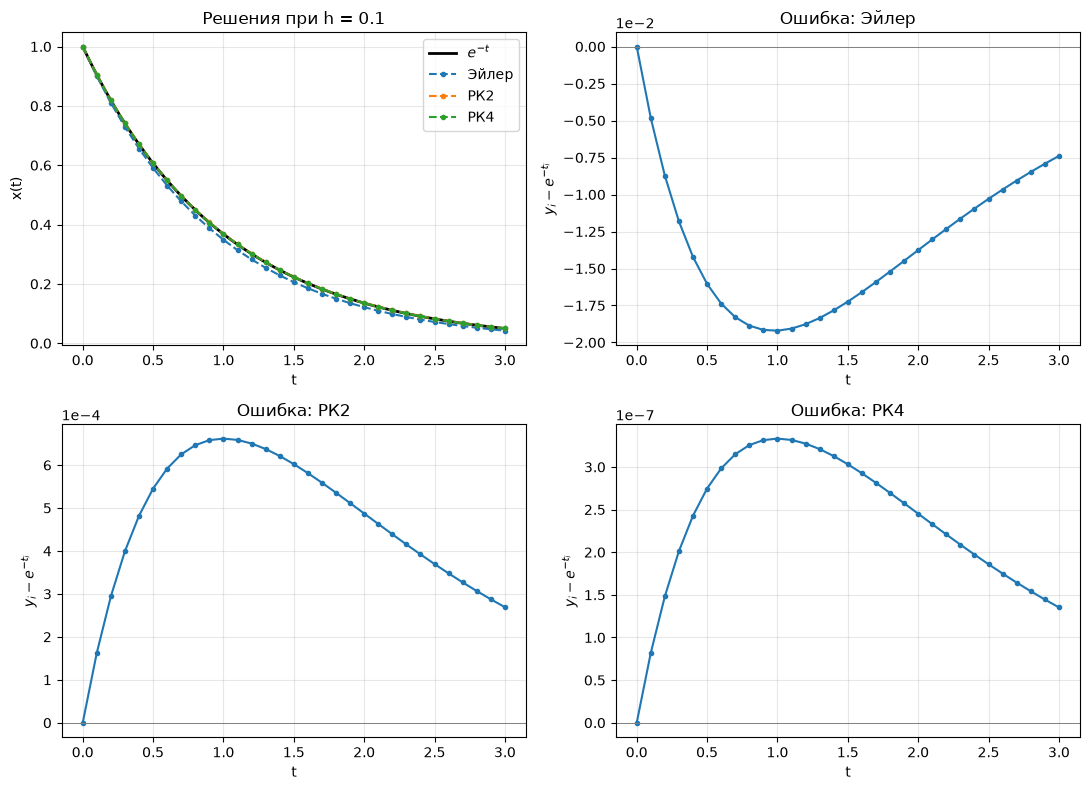

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
ax = axes[0, 0]
t_fine = np.linspace(t0, T, 601)
ax.plot(t_fine, exact(t_fine), "k-", linewidth=2, label=r"$e^{-t}$")
for name, _, _ in methods:
    ax.plot(t_grid, solutions[name], "o--", markersize=3, label=name)
ax.set(xlabel="t", ylabel="x(t)", title=f"Решения при h = {(T-t0)/N:g}")
ax.legend()

for ax, (name, _, _) in zip([axes[0, 1], axes[1, 0], axes[1, 1]], methods):
    ax.plot(t_grid, solutions[name] - x_exact, "o-", markersize=3)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.set(xlabel="t", ylabel=r"$y_i-e^{-t_i}$", title="Ошибка: " + name)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
for ax in axes.flat:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Проверка порядка точности.

Для всех методов используем одни и те же сгущающиеся сетки.
Определим глобальную ошибку как максимум по всем узлам, включая края:

$$
    E_N=\max_{0\le i\le N}|y_i-e^{-t_i}|.
$$

Если $E_N\approx Ch^p$, то при удвоении числа шагов

$$
    p_{\mathrm{набл}}=\log_2\frac{E_N}{E_{2N}}\longrightarrow p.
$$

Ожидаем $p=1,2,4$, то есть уменьшение ошибки примерно в $2,4,16$ раз.

In [7]:
N_values = np.array([15, 30, 60, 120, 240, 480])
convergence = {}
for name, step, theoretical_order in methods:
    errors = []
    orders = []
    print("\nМетод:", name)
    print(f"{'N':>6} {'h':>12} {'E_N':>16} {'Порядок':>12}")
    for n in N_values:
        t, y = solve_ode(f, t0, T, x0, n, step)
        error = np.max(np.abs(y - exact(t)))
        order = np.log2(errors[-1]/error) if errors and error > 0 else np.nan
        order_text = f"{order:.5f}" if np.isfinite(order) else "—"
        print(f"{n:6d} {(T-t0)/n:12.6f} {error:16.6e} {order_text:>12}")
        errors.append(error)
        orders.append(order)
    convergence[name] = dict(errors=np.array(errors), orders=np.array(orders))


Метод: Эйлер
     N            h              E_N      Порядок
    15     0.200000     4.019944e-02            —
    30     0.100000     1.920100e-02      1.06599
    60     0.050000     9.393519e-03      1.03144
   120     0.025000     4.647001e-03      1.01537
   240     0.012500     2.311297e-03      1.00760
   480     0.006250     1.152626e-03      1.00378

Метод: РК2
     N            h              E_N      Порядок
    15     0.200000     2.860402e-03            —
    30     0.100000     6.615437e-04      2.11231
    60     0.050000     1.591805e-04      2.05517
   120     0.025000     3.904855e-05      2.02732
   240     0.012500     9.670584e-06      2.01359
   480     0.006250     2.406311e-06      2.00678

Метод: РК4
     N            h              E_N      Порядок
    15     0.200000     5.796954e-06            —
    30     0.100000     3.332411e-07      4.12066
    60     0.050000     1.997610e-08      4.06022
   120     0.025000     1.222742e-09      4.03008
   240     0

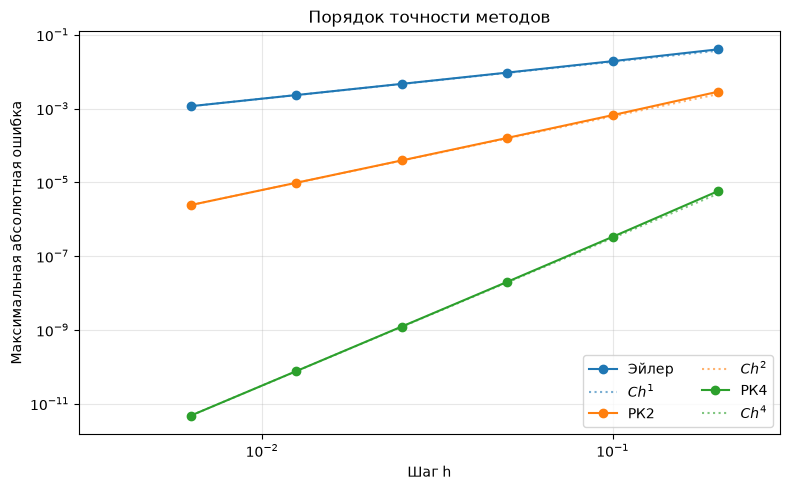

In [8]:
h_values = (T-t0) / N_values
fig, ax = plt.subplots(figsize=(8, 5))
for name, _, order in methods:
    errors = convergence[name]["errors"]
    line, = ax.loglog(h_values, errors, "o-", label=name)
    reference = errors[-1] * (h_values/h_values[-1])**order
    ax.loglog(h_values, reference, ":", color=line.get_color(), alpha=0.6,
              label=rf"$C h^{order}$")
ax.set(xlabel="Шаг h", ylabel="Максимальная абсолютная ошибка",
       title="Порядок точности методов")
ax.set_xticks([1e-3, 1e-2, 1e-1, 1],
              [r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", r"$10^0$"])
ax.set_xlim(3e-3, 0.3)
ax.minorticks_off()
ax.grid(True, alpha=0.3)
ax.legend(ncols=2)
fig.tight_layout()
plt.show()

## Устойчивость и независимая проверка.

Для $x'=-x$ каждый шаг умножает решение на свой коэффициент:

$$
\begin{aligned}
    R_1(h)&=1-h,\\
    R_2(h)&=1-h+\frac{h^2}{2},\\
    R_4(h)&=1-h+\frac{h^2}{2}-\frac{h^3}{6}+\frac{h^4}{24}.
\end{aligned}
$$

Возмущения убывают при $|R(h)|<1$. Для Эйлера и РК2 это $0<h<2$;
для классического РК4 вдоль отрицательной вещественной оси —
приблизительно $0<h<2.7853$.
Все использованные для сравнения шаги лежат внутри этих интервалов.

При $0<h<1$ для Эйлера имеем $1-h<e^{-h}$, поэтому численное
решение ниже точного. Для РК2 и РК4 соответствующие многочлены
выше $e^{-h}$ при $h>0$, что объясняет знак ошибок на графиках.

Проверим реализацию по формулам $y_i=R(h)^i$, полученным непосредственно
из схем. Это отдельная проверка кода; порядок выше проверен по точному
решению $e^{-t}$.

In [9]:
h = (T-t0)/N
factors = {"Эйлер": 1-h,
           "РК2": 1-h+h**2/2,
           "РК4": 1-h+h**2/2-h**3/6+h**4/24}
print(f"{'Метод':<10} {'R(h)':>16} {'max |y_i - R^i|':>21}")
for name, _, _ in methods:
    powers = x0 * factors[name]**np.arange(N+1)
    difference = np.max(np.abs(solutions[name] - powers))
    print(f"{name:<10} {factors[name]:16.12f} {difference:21.5e}")
    assert abs(factors[name]) < 1
    assert difference < 1e-13
    assert solutions[name][0] == x0
print("Начальное условие и формулы сеточного решения проверены.")

Метод                  R(h)       max |y_i - R^i|
Эйлер        0.900000000000           1.11022e-16
РК2          0.905000000000           1.11022e-16
РК4          0.904837500000           3.33067e-16
Начальное условие и формулы сеточного решения проверены.


## Ответ.

Точное решение задачи Коши:

$$
    \boxed{x(t)=e^{-t}}.
$$

Численные решения на равномерной сетке $t_i=ih$ имеют вид

$$
\boxed{
\begin{aligned}
    y_i^{\mathrm{Э}}&=(1-h)^i,\\
    y_i^{\mathrm{РК2}}&=\left(1-h+\frac{h^2}{2}\right)^i,\\
    y_i^{\mathrm{РК4}}&=\left(1-h+\frac{h^2}{2}-\frac{h^3}{6}
    +\frac{h^4}{24}\right)^i.
\end{aligned}}
$$

Таблицы и графики показывают сходимость к $e^{-t}$.
Наблюдаемые глобальные порядки стремятся к $1$, $2$ и $4$ соответственно.
При одинаковом шаге на рассмотренных сетках наиболее точен РК4.